# Sección 5.7 — Expansión del dominio experimental y Optimización Bayesiana

Este notebook reproduce exclusivamente el análisis computacional correspondiente a la sección 5.7 de la tesis.

El flujo implementado es:

1. Integración del conjunto Box–Behnken con las observaciones adicionales de expansión.
2. Ajuste de un modelo RSM cuadrático como referencia.
3. Ajuste de un Proceso Gaussiano (GP) sobre el dataset expandido.
4. Cálculo de la media predictiva y la incertidumbre del GP.
5. Implementación de la función de adquisición Expected Improvement (EI).
6. Búsqueda global aproximada del máximo de EI mediante muestreo aleatorio.
7. Propuesta de la siguiente condición experimental.

## Dominio real de búsqueda de BO

- pH: 2.0–6.5
- Sacarosa: 0.1–4.0 %
- Log(inóculo): 5.0–7.0

**Nota:** el conjunto de entrenamiento incluye algunas observaciones fuera de estos límites, pero la generación de candidatos de BO permanece restringida al dominio anterior.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import norm

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel

## 1. Dataset expandido

In [ ]:
variables = ["pH", "Sacarosa", "Log_inoc"]

df = pd.DataFrame({
    "pH": [
        4.5,6.5,4.5,6.5,4.5,6.5,4.5,6.5,5.5,5.5,5.5,5.5,5.5,
        3.741,3.378,2.98,3.096,3.845,3.329,3.806,2.571,
        4.684,5.487,5.504,5.135,2.1,2.2,2.6,3.0,3.4,3.8,3.2
    ],
    "Sacarosa": [
        1,1,4,4,2.5,2.5,2.5,2.5,1,4,1,4,2.5,
        0.501,1.107,0.58,0.184,0.355,0.845,0.552,0.511,
        2.584,2.565,3.06,2.537,1,2.5,2.5,2.5,2.5,2.5,2.5
    ],
    "Log_inoc": [
        6.70,6.70,6.70,6.70,5.00,5.00,7.00,7.00,5.00,5.00,7.00,7.00,6.70,
        5.4537,5.8462,6.4581,5.7961,5.3509,6.2688,5.7236,6.262,
        5.8617,5.6245,5.2312,6.7326,6,6,6,6,6,6,6
    ],





   "CisZ": [
    0.23151744, 0.1556604, 0.15039864, 0.08638056,
    0.12847464, 0.09471168, 0.11532024, 0.11356632,
    0.09076536, 0.06884136, 0.131544, 0.14206752,
    0.093988188, 0.1362708144, 0.0775583424, 0.1318421664,
    0.1093744512, 0.0754974864, 0.0642285504, 0.1195559568,
    0.1102601808, 0.0748134576, 0.1768652928, 0.091335384,
    0.0890640576, 0.1265540976, 0.096898007052, 0.115738571844,
    0.133208163144, 0.075422484996, 0.179794295352, 0.075480868008
]
})

df["origen"] = ["Box-Behnken"] * 13 + ["Expansión"] * (len(df)-13)

print(f"Número total de observaciones: {len(df)}")
display(df)

Número total de observaciones: 32


,pH,Sacarosa,Log_inoc,CisZ,origen
0,4.500,1.000,6.7000,0.231517,Box-Behnken
1,6.500,1.000,6.7000,0.155660,Box-Behnken
2,4.500,4.000,6.7000,0.150399,Box-Behnken
3,6.500,4.000,6.7000,0.086381,Box-Behnken
4,4.500,2.500,5.0000,0.128475,Box-Behnken
5,6.500,2.500,5.0000,0.094712,Box-Behnken
6,4.500,2.500,7.0000,0.115320,Box-Behnken
7,6.500,2.500,7.0000,0.113566,Box-Behnken
8,5.500,1.000,5.0000,0.090765,Box-Behnken
9,5.500,4.000,5.0000,0.068841,Box-Behnken


## 2. Dominio real de búsqueda de BO

In [ ]:
BO_BOUNDS = {
    "pH": (2.0, 6.5),
    "Sacarosa": (0.1, 4.0),
    "Log_inoc": (5.0, 7.0)
}

for variable, bounds in BO_BOUNDS.items():
    print(f"{variable}: {bounds}")

pH: (2.0, 6.5)
Sacarosa: (0.1, 4.0)
Log_inoc: (5.0, 7.0)


## 3. Escalado para el GP

El escalador se ajusta con el conjunto completo de entrenamiento. Los candidatos de BO se generan en unidades reales dentro de `BO_BOUNDS` y después se transforman con el mismo escalador.

In [ ]:
X = df[variables].copy()
y = df["CisZ"].values

scaler = MinMaxScaler()
Xs = scaler.fit_transform(X)

print("Mínimos observados:")
print(pd.Series(scaler.data_min_, index=variables))

print("\nMáximos observados:")
print(pd.Series(scaler.data_max_, index=variables))

Mínimos observados:
pH          2.100
Sacarosa    0.184
Log_inoc    5.000
dtype: float64

Máximos observados:
pH          6.5
Sacarosa    4.0
Log_inoc    7.0
dtype: float64


## 4. RSM cuadrático — dataset expandido

In [ ]:
modelo_rsm = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("reg", LinearRegression())
])

modelo_rsm.fit(X, y)
y_pred_rsm = modelo_rsm.predict(X)

r2_rsm = r2_score(y, y_pred_rsm)
rmse_rsm = np.sqrt(mean_squared_error(y, y_pred_rsm))

print(f"R² RSM   = {r2_rsm:.4f}")
print(f"RMSE RSM = {rmse_rsm:.2f}")

R² RSM   = 0.1747
RMSE RSM = 0.03


## 5. Proceso Gaussiano — dataset expandido

In [ ]:
kernel = (
    ConstantKernel(1.0, (0.001, 1000.0))
    * Matern(
        length_scale=[0.35, 0.35, 0.35],
        length_scale_bounds=(0.005, 5.0),
        nu=2.5
    )
    + WhiteKernel(
        noise_level=0.01,
        noise_level_bounds=(1e-8, 1.0)
    )
)

gp = GaussianProcessRegressor(
    kernel=kernel,
    normalize_y=True,
    n_restarts_optimizer=50,
    random_state=42
)

gp.fit(Xs, y)

print("Kernel GP optimizado:")
print(gp.kernel_)

Kernel GP optimizado:
0.992**2 * Matern(length_scale=[0.0171, 0.597, 0.101], nu=2.5) + WhiteKernel(noise_level=2.35e-08)


## 6. Expected Improvement

Se utiliza EI para maximización, con parámetro de exploración `xi = 3.73E-4`.

In [ ]:


XI=3.73E-4  #mg/L
def expected_improvement(mu, sigma, y_best, xi=XI):
    sigma = np.maximum(sigma, 1e-12)
    mejora = mu - y_best - xi
    z = mejora / sigma
    ei = mejora * norm.cdf(z) + sigma * norm.pdf(z)
    return np.maximum(ei, 0.0)

In [ ]:
xi_calculado = 0.01 * np.std(y)

print(f"ξ utilizado: {XI:.8f} mg/L")
print(f"ξ calculado: {xi_calculado:.8f} mg/L")
print(f"Diferencia: {abs(XI - xi_calculado):.8f} mg/L")

ξ utilizado: 0.00037300 mg/L
ξ calculado: 0.00036742 mg/L
Diferencia: 0.00000558 mg/L


## 7. Búsqueda global aproximada del máximo de EI

Se generan 250 000 candidatos uniformemente distribuidos dentro del dominio real de BO.

In [ ]:
def generar_candidatos_bo(n_random=250000, seed=42):
    rng = np.random.default_rng(seed)

    return pd.DataFrame({
        variable: rng.uniform(
            BO_BOUNDS[variable][0],
            BO_BOUNDS[variable][1],
            size=n_random
        )
        for variable in variables
    })


def proponer_siguiente_experimento(gp, scaler, df, n_random=250000, xi=XI, seed=42):
    candidatos = generar_candidatos_bo(n_random=n_random, seed=seed)
    candidatos_s = scaler.transform(candidatos[variables])

    mu, sigma = gp.predict(candidatos_s, return_std=True)

    y_best = float(df["CisZ"].max())
    ei = expected_improvement(mu, sigma, y_best, xi=XI)

    idx = int(np.argmax(ei))

    return {
        "punto": candidatos.iloc[idx].copy(),
        "mu": float(mu[idx]),
        "sigma": float(sigma[idx]),
        "ei": float(ei[idx]),
        "y_best": y_best
    }


resultado_bo = proponer_siguiente_experimento(
    gp=gp,
    scaler=scaler,
    df=df,
    n_random=250000,
    xi=XI,
    seed=42
)

punto_bo = resultado_bo["punto"]
mu_bo = resultado_bo["mu"]
sigma_bo = resultado_bo["sigma"]
ei_bo = resultado_bo["ei"]
y_best = resultado_bo["y_best"]

## 8. Condición propuesta por BO

In [ ]:
mejor_exp = df.loc[df["CisZ"].idxmax()]

tabla_bo = pd.DataFrame({
    "Variable / métrica": [
        "pH propuesto",
        "Sacarosa propuesta (%)",
        "Log(inóculo) propuesto",
        "Media GP predicha (mg/L)",
        "Desviación estándar GP σ (mg/L)",
        "Expected Improvement",
        "Mejor CisZ experimental (mg/L)",
        "pH mejor experimento",
        "Sacarosa mejor experimento (%)",
        "Log(inóculo) mejor experimento"
    ],
    "Valor": [
        punto_bo["pH"],
        punto_bo["Sacarosa"],
        punto_bo["Log_inoc"],
        mu_bo,
        sigma_bo,
        ei_bo,
        mejor_exp["CisZ"],
        mejor_exp["pH"],
        mejor_exp["Sacarosa"],
        mejor_exp["Log_inoc"]
    ]
})

tabla_bo["Valor"] = tabla_bo["Valor"].astype(float).round(4)
display(tabla_bo)

,Variable / métrica,Valor
0,pH propuesto,4.4982
1,Sacarosa propuesta (%),0.7851
2,Log(inóculo) propuesto,6.6438
3,Media GP predicha (mg/L),0.2256
4,Desviación estándar GP σ (mg/L),0.0128
5,Expected Improvement,0.0026
6,Mejor CisZ experimental (mg/L),0.2315
7,pH mejor experimento,4.5000
8,Sacarosa mejor experimento (%),1.0000
9,Log(inóculo) mejor experimento,6.7000


## 9. Plano de visualización pH–Log(inóculo)

Para alinear la visualización con la sección 5.8 de la tesis, la media GP, la incertidumbre y EI se representan en el plano pH-Sacarosa, manteniendo log(inoculo) fijo el valor propuesto por BO.

In [ ]:


# ============================================================
# PLANO DE VISUALIZACIÓN pH–SACAROSA
# Log(inóculo) fijo en el valor propuesto por BO
# ============================================================

log_inoc_fijo = float(punto_bo["Log_inoc"])
n_malla = 180

ph = np.linspace(
    BO_BOUNDS["pH"][0],
    BO_BOUNDS["pH"][1],
    n_malla
)

sacarosa = np.linspace(
    BO_BOUNDS["Sacarosa"][0],
    BO_BOUNDS["Sacarosa"][1],
    n_malla
)

PH, SAC = np.meshgrid(ph, sacarosa)

malla = pd.DataFrame({
    "pH": PH.ravel(),
    "Sacarosa": SAC.ravel(),
    "Log_inoc": log_inoc_fijo
})

malla_s = scaler.transform(
    malla[variables]
)

mu_malla, sigma_malla = gp.predict(
    malla_s,
    return_std=True
)

Z_mu = mu_malla.reshape(PH.shape)
Z_sigma = sigma_malla.reshape(PH.shape)

print(
    f"Log(inóculo) fijo para visualización: "
    f"{log_inoc_fijo:.4f}"
)

Log(inóculo) fijo para visualización: 6.6438


## 10. Figura — media posterior del GP

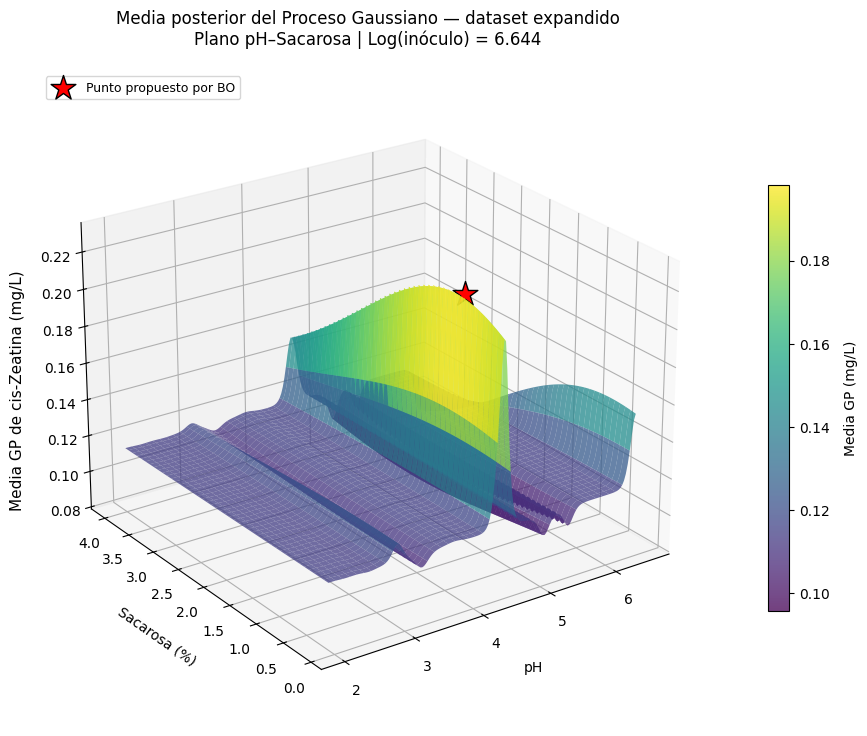

In [ ]:
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")

superficie = ax.plot_surface(
    PH,
    SAC,
    Z_mu,
    cmap="viridis",
    alpha=0.75,
    edgecolor="none"
)

# Punto propuesto por BO
ax.scatter(
    punto_bo["pH"],
    punto_bo["Sacarosa"],
    mu_bo,
    marker="*",
    s=350,
    color="red",
    edgecolor="black",
    depthshade=False,
    label="Punto propuesto por BO"
)

# Ejes
ax.set_xlabel("pH", labelpad=10)
ax.set_ylabel("Sacarosa (%)", labelpad=10)

# Evitar recorte de la etiqueta vertical
ax.set_zlabel("")

fig.text(
    0.095,
    0.50,
    "Media GP de cis-Zeatina (mg/L)",
    rotation=90,
    va="center",
    ha="center",
    fontsize=11
)

# Título correcto
ax.set_title(
    "Media posterior del Proceso Gaussiano — dataset expandido\n"
    f"Plano pH–Sacarosa | Log(inóculo) = {log_inoc_fijo:.3f}",
    pad=18
)

# Barra de color
barra = fig.colorbar(
    superficie,
    ax=ax,
    shrink=0.65,
    pad=0.08
)

barra.set_label(
    "Media GP (mg/L)",
    labelpad=10
)

# Leyenda y ángulo de visualización
ax.legend(
    loc="upper left",
    fontsize=9
)

ax.view_init(
    elev=24,
    azim=235
)

plt.subplots_adjust(
    left=0.08,
    right=0.90,
    bottom=0.08,
    top=0.90
)

plt.savefig(
    "GP_media_dataset_expandido.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.15
)

plt.show()

## 11. Figura — incertidumbre predictiva

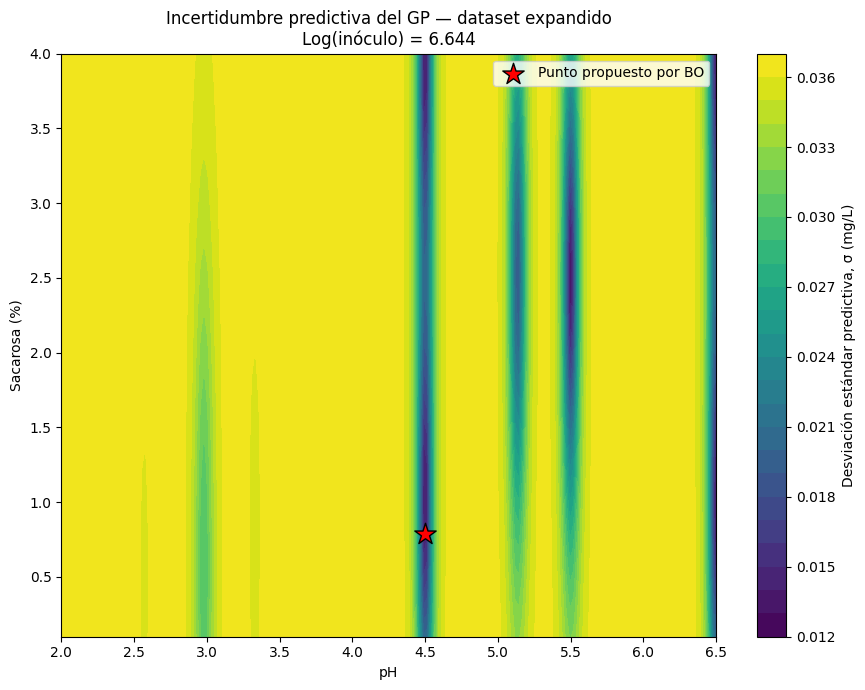

In [ ]:
plt.figure(figsize=(9, 7))

contorno = plt.contourf(
    PH,
    SAC,
    Z_sigma,
    levels=28,
    cmap="viridis"
)

barra = plt.colorbar(contorno)

barra.set_label(
    "Desviación estándar predictiva, σ (mg/L)"
)

# Punto propuesto por BO
plt.scatter(
    punto_bo["pH"],
    punto_bo["Sacarosa"],
    marker="*",
    s=260,
    color="red",
    edgecolor="black",
    label="Punto propuesto por BO"
)

plt.xlabel("pH")
plt.ylabel("Sacarosa (%)")

plt.title(
    "Incertidumbre predictiva del GP — dataset expandido\n"
    f"Log(inóculo) = {log_inoc_fijo:.3f}"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    "GP_incertidumbre_dataset_expandido.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.15
)

plt.show()

## 12. Figura — Expected Improvement

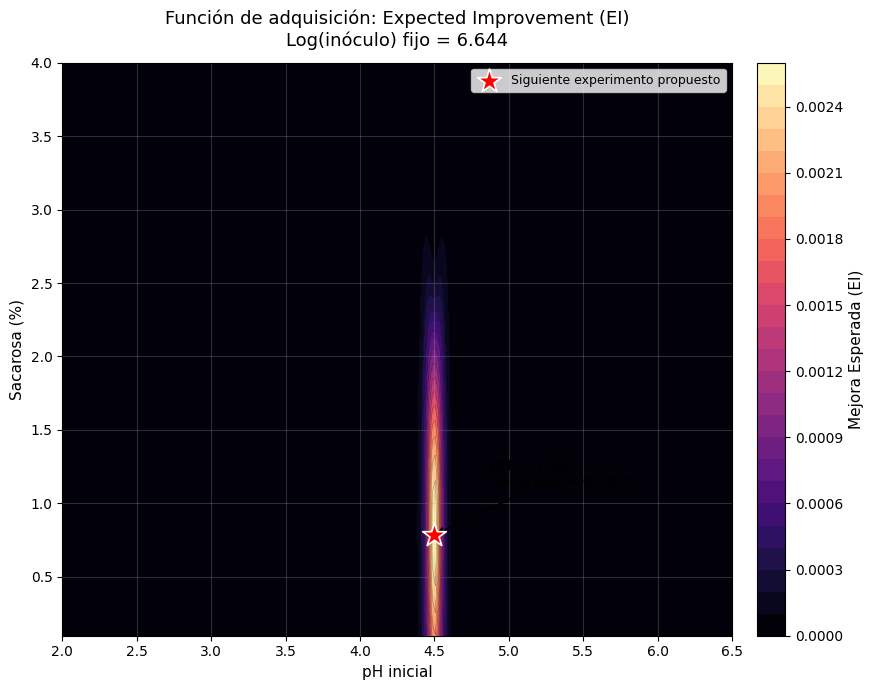

Plano utilizado para visualizar EI:
Log(inóculo) fijo = 6.6438

Punto propuesto por la BO:
pH            = 4.4982
Sacarosa      = 0.7851 %
Log(inóculo)  = 6.6438
EI máximo     = 0.0026


In [ ]:
# ============================================================
# MAPA 2D DE EXPECTED IMPROVEMENT
# Plano pH – Sacarosa
# Log(inóculo) fijo en el valor propuesto por BO
# ============================================================

# Log(inóculo) propuesto por la BO
log_inoc_fijo_ei = float(punto_bo["Log_inoc"])

# Resolución de la malla
n_malla_ei = 220

# Dominio REAL de búsqueda de la BO
ph_ei = np.linspace(
    BO_BOUNDS["pH"][0],
    BO_BOUNDS["pH"][1],
    n_malla_ei
)

sacarosa_ei = np.linspace(
    BO_BOUNDS["Sacarosa"][0],
    BO_BOUNDS["Sacarosa"][1],
    n_malla_ei
)

# Malla pH – Sacarosa
PH_EI, SAC_EI = np.meshgrid(
    ph_ei,
    sacarosa_ei
)

# Construcción del plano manteniendo Log(inóculo) constante
malla_ei = pd.DataFrame({
    "pH": PH_EI.ravel(),
    "Sacarosa": SAC_EI.ravel(),
    "Log_inoc": log_inoc_fijo_ei
})

# Escalar con el mismo scaler utilizado por el GP
malla_ei_s = scaler.transform(
    malla_ei[variables]
)

# Predicción del GP
mu_ei, sigma_ei = gp.predict(
    malla_ei_s,
    return_std=True
)

# Expected Improvement
EI = expected_improvement(
    mu_ei,
    sigma_ei,
    y_best,
    xi=XI
)

Z_EI = EI.reshape(PH_EI.shape)


# ============================================================
# GRÁFICA
# ============================================================

fig, ax = plt.subplots(figsize=(9, 7))

contorno = ax.contourf(
    PH_EI,
    SAC_EI,
    Z_EI,
    levels=30,
    cmap="magma"
)

# Líneas de contorno
ax.contour(
    PH_EI,
    SAC_EI,
    Z_EI,
    levels=15,
    colors="black",
    linewidths=0.35,
    alpha=0.45
)

# Barra de color
barra = fig.colorbar(
    contorno,
    ax=ax,
    pad=0.03
)

barra.set_label(
    "Mejora Esperada (EI)",
    fontsize=11
)


# ============================================================
# PUNTO PROPUESTO POR BO
# ============================================================

ax.scatter(
    punto_bo["pH"],
    punto_bo["Sacarosa"],
    marker="*",
    s=320,
    color="red",
    edgecolor="white",
    linewidth=1.2,
    zorder=10,
    label="Siguiente experimento propuesto"
)

# Coordenadas mostradas junto al punto
texto = (
    f"pH = {punto_bo['pH']:.2f}\n"
    f"Sacarosa = {punto_bo['Sacarosa']:.2f} %"
)

ax.annotate(
    texto,
    xy=(
        punto_bo["pH"],
        punto_bo["Sacarosa"]
    ),
    xytext=(40, 35),
    textcoords="offset points",
    fontsize=10,
    fontweight="bold",
    arrowprops=dict(
        arrowstyle="->",
        linewidth=1.3
    )
)


# ============================================================
# FORMATO
# ============================================================

ax.set_xlabel(
    "pH inicial",
    fontsize=11
)

ax.set_ylabel(
    "Sacarosa (%)",
    fontsize=11
)

ax.set_title(
    "Función de adquisición: Expected Improvement (EI)\n"
    f"Log(inóculo) fijo = {log_inoc_fijo_ei:.3f}",
    fontsize=13,
    pad=12
)

ax.set_xlim(
    BO_BOUNDS["pH"]
)

ax.set_ylim(
    BO_BOUNDS["Sacarosa"]
)

ax.grid(
    alpha=0.25
)

ax.legend(
    loc="upper right",
    fontsize=9
)

plt.tight_layout()

# Guardar para la tesis
plt.savefig(
    "Expected_Improvement_pH_Sacarosa.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.15
)

plt.show()


# ============================================================
# INFORMACIÓN NUMÉRICA
# ============================================================

print("Plano utilizado para visualizar EI:")
print(f"Log(inóculo) fijo = {log_inoc_fijo_ei:.4f}")

print("\nPunto propuesto por la BO:")
print(f"pH            = {punto_bo['pH']:.4f}")
print(f"Sacarosa      = {punto_bo['Sacarosa']:.4f} %")
print(f"Log(inóculo)  = {punto_bo['Log_inoc']:.4f}")
print(f"EI máximo     = {ei_bo:.4f}")

## 13. Diagnóstico RSM — observado vs. predicho

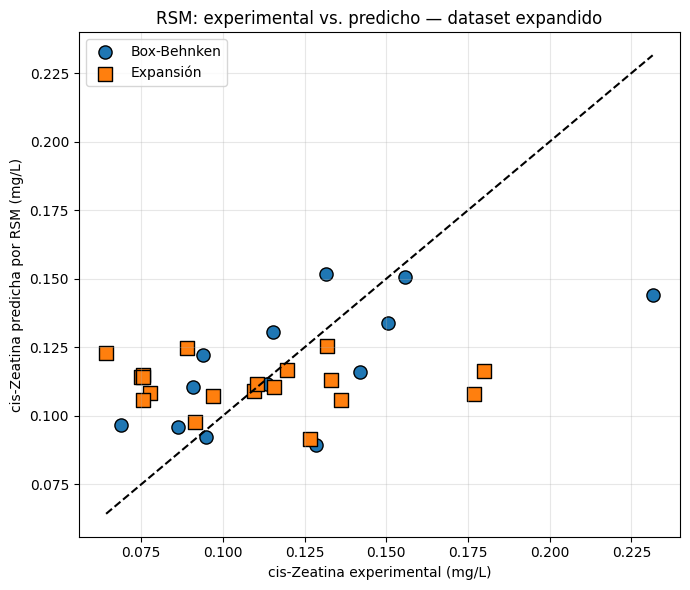

In [ ]:
plt.figure(figsize=(7, 6))

df_diag = df.copy()
df_diag["CisZ_predicha_RSM"] = y_pred_rsm

for origen, marker in [("Box-Behnken", "o"), ("Expansión", "s")]:
    dfo = df_diag[df_diag["origen"] == origen]
    plt.scatter(
        dfo["CisZ"],
        dfo["CisZ_predicha_RSM"],
        s=90,
        marker=marker,
        edgecolor="black",
        label=origen
    )

min_val = min(df_diag["CisZ"].min(), df_diag["CisZ_predicha_RSM"].min())
max_val = max(df_diag["CisZ"].max(), df_diag["CisZ_predicha_RSM"].max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--",
    color="black"
)

plt.xlabel("cis-Zeatina experimental (mg/L)")
plt.ylabel("cis-Zeatina predicha por RSM (mg/L)")
plt.title("RSM: experimental vs. predicho — dataset expandido")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 14. Resumen reproducible

In [ ]:
resumen = pd.DataFrame({
    "Métrica": [
        "Número total de observaciones",
        "R² RSM expandido",
        "RMSE RSM expandido",
        "pH propuesto por BO",
        "Sacarosa propuesta por BO (%)",
        "Log(inóculo) propuesto por BO",
        "Media GP punto BO (mg/L)",
        "σ GP punto BO (mg/L)",
        "Expected Improvement",
        "Mejor cis-Zeatina observada (mg/L)"
    ],
    "Valor": [
        len(df),
        round(r2_rsm, 4),
        round(rmse_rsm, 2),
        round(float(punto_bo["pH"]), 4),
        round(float(punto_bo["Sacarosa"]), 4),
        round(float(punto_bo["Log_inoc"]), 4),
        round(mu_bo, 4),
        round(sigma_bo, 4),
        round(ei_bo, 4),
        round(y_best, 4)
    ]
})

display(resumen)

print("\nKernel GP optimizado:")
print(gp.kernel_)

print("\nDominio real de BO:")
for variable, bounds in BO_BOUNDS.items():
    print(f"{variable}: {bounds}")

,Métrica,Valor
0,Número total de observaciones,32.0000
1,R² RSM expandido,0.1747
2,RMSE RSM expandido,0.0300
3,pH propuesto por BO,4.4982
4,Sacarosa propuesta por BO (%),0.7851
5,Log(inóculo) propuesto por BO,6.6438
6,Media GP punto BO (mg/L),0.2256
7,σ GP punto BO (mg/L),0.0128
8,Expected Improvement,0.0026
9,Mejor cis-Zeatina observada (mg/L),0.2315



Kernel GP optimizado:
0.992**2 * Matern(length_scale=[0.0171, 0.597, 0.101], nu=2.5) + WhiteKernel(noise_level=2.35e-08)

Dominio real de BO:
pH: (2.0, 6.5)
Sacarosa: (0.1, 4.0)
Log_inoc: (5.0, 7.0)
